# 공시 변화 기반 재무위험 조기경보 — ML 노트북

2026 D&A ML Competition 가점 제출용입니다. 가점 4항목에 맞춰 장을 나눴습니다.

| 가점 항목 | 위치 |
|---|---|
| 수업 모델 활용 | 4장 (Logistic Regression, Decision Tree, Random Forest) |
| 모델 선택 근거 | 3장, 5장 |
| 검증 | 2장 (시간 기준 분할·누수 방지), 4장 (불균형 지표) |
| 실험·해석 | 5장 (변수 해석), 6장 (문구 변수 실험), 7장 (운영 임계값), 8장 (연도별 안정성) |

처음부터 끝까지 실행하면 같은 결과가 나옵니다 (`random_state` 고정). 데이터 파일은 `data/processed/panel.csv`입니다.

## 0. 문제와 라벨 정의

- **예측 시점**: t년 사업보고서 제출일. 변수는 이 보고서와 t년 공시로만 만든다.
- **위험 사건(label=1)**: 제출일 + 30일 이후 1년 안에 ① 관리종목 지정 ② 상장폐지 사유 발생·결정
- **제외(label 없음)**: 제출 직후 30일 안에 사건이 난 행. 이미 공개된 감사의견 때문에 바로 생긴 사건이라 예측 문제가 아니다.
- **단위**: 기업 × 사업연도 (2018~2024)
- **표본**: 사건 기업 469곳 전부 + 현재 상장 기업 무작위 300곳. 상장폐지 기업은 현재 상장 목록에 없으므로 따로 넣어야 생존 편향을 막을 수 있다.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score, roc_auc_score, precision_score, recall_score
from sklearn.tree import export_text
from dart_agent import model as M
from dart_agent.synthetic import make_panel

USE_SYNTHETIC = False   # True면 데이터 없이 구조만 확인하는 합성 데이터
TEST_START = 2022       # 2018~2021 학습, 2022~2024 평가
pd.set_option("display.width", 140)
plt.rcParams["axes.unicode_minus"] = False

## 1. 데이터 출처

| 데이터 | 제공처 | 접근 방법 | 라이선스 | 수집일 | 범위·건수 | 전처리 |
|---|---|---|---|---|---|---|
| 전체 재무제표 (사업보고서) | 금융감독원 OpenDART | 단일회사 전체 재무제표 API (`fnlttSinglAcntAll`) | OpenDART 이용약관 | 2026-11-07 ~ 11-10 | 769개 기업 × 2018~2024 = 5,383건 요청 → 사업보고서 있는 3,680건 | 연결 우선(없으면 별도), 계정 8개 추출 → 재무비율 |
| 감사의견·강조사항 | 금융감독원 OpenDART | 정기보고서 주요정보 API (회계감사인 명칭 및 감사의견) | OpenDART 이용약관 | 2026-11-07 ~ 11-10 | 위와 같음 | 당기 행 선택, 비적정 여부·계속기업 언급 이진화 |
| 공시 목록 | 금융감독원 OpenDART | 공시검색 API (`list`) | OpenDART 이용약관 | 2026-11-07 ~ 11-10 | 위와 같음 | 최대주주 변경·CB/BW/EB·유상증자·정기보고서 정정 건수 |
| 사업보고서·감사보고서 원문 | 금융감독원 OpenDART | 공시서류원본 API (`document`) | OpenDART 이용약관 | 2026-11-07 ~ 11-10 | 문구 변수 있는 행: 감사 66%, 주석 84% | `<TITLE>`로 섹션 분리, 숫자 제거, 전년 대비 TF-IDF 유사도, 새 경고 문구 |
| 거래소공시 (라벨) | 금융감독원 OpenDART (한국거래소 제출 공시) | 공시검색 API (`pblntf_ty=I`), 월 단위 | OpenDART 이용약관 | 2026-11-10 | 2018-01 ~ 2026-11, 사건 1,763건 / 512개 기업 | 관리종목 지정·상장폐지 사유 발생·결정만, 해제·합병·스팩·해외시장 제외 |
| 기업 고유번호 목록 (표본) | 금융감독원 OpenDART | 고유번호 API (`corpCode.xml`) | OpenDART 이용약관 | 2026-11-07 | 상장 기업 중 무작위 300곳 (seed 42) | 스팩 제외 |

수집 코드: `scripts/build_labels.py`, `scripts/build_dataset.py`. 상세 정의는 `docs/data_sources.md`.

In [2]:
if USE_SYNTHETIC:
    df = make_panel()
else:
    df = pd.read_csv(ROOT / "data/processed/panel.csv", dtype={"corp_code": str})
print("행", len(df), "/ 기업", df.corp_code.nunique())
print("라벨:", df["label"].value_counts(dropna=False).rename({0.0: "안전(0)", 1.0: "위험(1)"}).to_dict())
df.dropna(subset=["label"]).groupby("year")["label"].agg(행="count", 위험비율="mean").round(3).T

행 3680 / 기업 620
라벨: {'안전(0)': 2981, '위험(1)': 628, nan: 71}


year,2018,2019,2020,2021,2022,2023,2024
행,494.0,494.000,517.000,512.000,516.000,539.000,537.000
위험비율,0.2,0.219,0.203,0.141,0.163,0.174,0.123


## 2. 검증 설계 — 시간 기준 분할과 누수 방지

- 무작위로 섞어 나누면 미래 연도의 정보가 학습에 들어가 성능이 부풀려진다. 그래서 **과거(2018~2021)로 학습하고 미래(2022~2024)로 평가**한다.
- 변수는 t년 사업보고서와 t년 공시로만 만들고, 사건은 그 보고서 **제출일 이후**에서만 찾는다.
- 제출 직후 30일 안에 난 사건 71건은 학습·평가에서 뺐다. 이 행을 1로 두면 '감사의견 비적정 → 바로 관리종목' 같은 당연한 연결을 맞히는 것만으로 성능이 부풀려진다.

In [3]:
FIN = [f for f in M.FINANCIAL_FEATURES if f in df.columns]
TEXT = [f for f in M.TEXT_FEATURES if f in df.columns]
ALL = FIN + TEXT

train, test = M.time_split(df, TEST_START)   # label 없는 행은 여기서 빠진다
assert train.year.max() < test.year.min()
print(f"train {train.year.min()}~{train.year.max()}: {len(train)}행, 위험 {train.label.mean():.1%}")
print(f"test  {test.year.min()}~{test.year.max()}: {len(test)}행, 위험 {test.label.mean():.1%}")
print("변수", len(ALL), "개 (재무·공시 이벤트", len(FIN), "+ 문구", len(TEXT), ")")

train 2018~2021: 2017행, 위험 19.0%
test  2022~2024: 1592행, 위험 15.3%
변수 19 개 (재무·공시 이벤트 16 + 문구 3 )


## 3. 모델 선택 근거

- **Logistic Regression (기본 모델)**: 금융 실무에서는 '왜 위험한가'를 설명해야 한다. 표준화 계수의 부호와 크기로 각 변수가 위험을 올리는지 내리는지 바로 읽을 수 있고, Agent 리포트의 근거(기업별 변수 기여도)도 여기서 나온다.
- **Decision Tree (해석 보조)**: '조건 A이고 B면 위험' 같은 규칙으로 판단 과정을 보여준다. 깊이를 4로 제한해 사람이 읽을 수 있게 했다.
- **Random Forest (성능 비교 기준)**: 변수 간 비선형 관계를 잡아 이 데이터로 낼 수 있는 성능 상한을 가늠한다. 설명력이 떨어지므로 Logistic과 성능이 비슷하면 Logistic을 쓴다.

**데이터 특성에 맞춘 처리**
- **불균형**: 위험 비율이 15~20%라 세 모델 모두 `class_weight="balanced"`로 소수 클래스에 가중치를 준다.
- **극단값**: 매출이 거의 없는 기업은 영업이익률 -594배, 매출 증가율 1,498배처럼 값이 튄다. 이 값이 Logistic 계수를 뒤틀어 '영업이익률이 높을수록 위험' 같은 거꾸로 된 해석이 나왔다. 그래서 학습 데이터의 1%·99% 분위수에서 자른다 (`QuantileClipper`).
- **결측**: 문구 변수는 전년 보고서가 없거나 원문이 없으면 비어 있다. 학습 데이터의 중앙값으로 채운다.

## 4. 학습과 평가

위험 비율이 15%라 모두 '안전'으로 찍어도 Accuracy는 85%가 된다. 그래서 Accuracy 대신 아래 지표를 쓴다.

- **Recall**: 실제 위험 기업 중 놓치지 않은 비율. 조기경보에서 가장 중요하다.
- **Precision**: 위험하다고 표시한 기업 중 실제 위험 기업 비율.
- **PR-AUC**: 임계값과 무관한 소수 클래스 탐지 성능. 무작위 기준선 = 위험 비율(0.153).
- ROC-AUC는 참고용으로 함께 보고한다.

In [4]:
models = M.build_models()
res = M.evaluate(models, train[ALL], train.label, test[ALL], test.label)
res.assign(PR_AUC_배수=lambda r: r.pr_auc / r.positive_rate_test).round(3)

,recall,precision,pr_auc,roc_auc,positive_rate_test,PR_AUC_배수
model,,,,,,
Logistic,0.672,0.360,0.439,0.788,0.153,2.863
DecisionTree,0.664,0.334,0.376,0.752,0.153,2.454
RandomForest,0.607,0.400,0.436,0.803,0.153,2.842


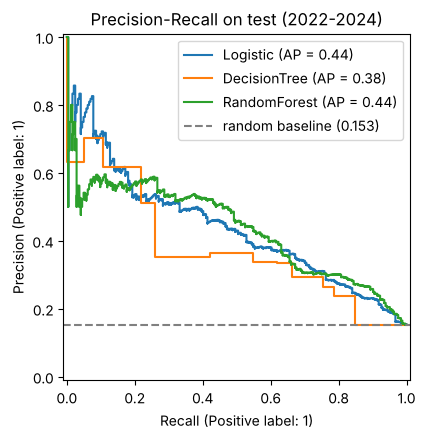

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, m in models.items():
    PrecisionRecallDisplay.from_estimator(m, test[ALL], test.label, name=name, ax=ax)
ax.axhline(test.label.mean(), ls="--", c="gray", label=f"random baseline ({test.label.mean():.3f})")
ax.set_title("Precision-Recall on test (2022-2024)")
ax.legend(loc="upper right")
plt.show()

**결과 요약 (평가: 2022~2024, 1,592행, 위험 비율 15.3%)**

- 세 모델 모두 무작위 기준선(PR-AUC 0.153)의 **약 2.5~2.9배**를 낸다. 공시 데이터만으로 위험 기업을 상당 부분 미리 가려낼 수 있다는 뜻이다.
- **Logistic(PR-AUC 0.439)과 Random Forest(0.436)의 성능이 거의 같다.** 비선형 모델로 바꿔도 얻는 것이 없으므로, 설명이 쉬운 Logistic을 Agent의 기본 모델로 쓴다 (3장의 선택 근거를 데이터로 확인).
- Logistic은 실제 위험 기업 3곳 중 2곳을 잡아낸다 (Recall 0.67). Random Forest는 덜 잡는 대신 정밀도가 조금 높다 (Recall 0.61, Precision 0.40).
- Decision Tree는 깊이 4로 제한한 대가로 성능이 가장 낮지만(PR-AUC 0.376), 아래 5장처럼 판단 규칙을 그대로 보여준다.

## 5. 해석 — 어떤 변수가 위험을 가르는가

In [6]:
coef = M.feature_importance(models["Logistic"], ALL).rename("Logistic 표준화 계수 (+면 위험 증가)")
rf = M.feature_importance(models["RandomForest"], ALL).rename("RandomForest 중요도")
pd.concat([coef, rf], axis=1).sort_values("RandomForest 중요도", ascending=False).round(3)

,Logistic 표준화 계수 (+면 위험 증가),RandomForest 중요도
roa,-0.423,0.156
operating_margin,0.154,0.129
roa_change,0.233,0.080
n_convertible_bond,0.232,0.077
ocf_to_assets,0.005,0.074
debt_to_assets,0.016,0.069
revenue_growth,-0.177,0.067
debt_to_assets_change,0.009,0.057
audit_text_change,-0.045,0.053
notes_text_change,-0.041,0.052


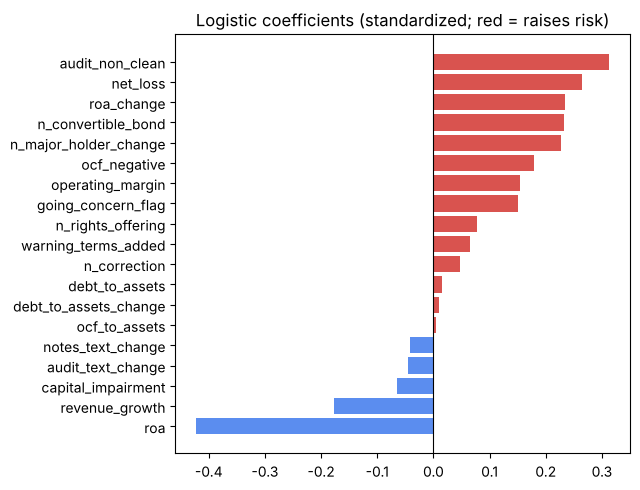

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
c = coef.sort_values()
ax.barh(c.index, c.values, color=["#d9534f" if v > 0 else "#5b8def" for v in c.values])
ax.axvline(0, c="black", lw=0.8)
ax.set_title("Logistic coefficients (standardized; red = raises risk)")
plt.tight_layout(); plt.show()

In [8]:
print(export_text(models["DecisionTree"].named_steps["clf"], feature_names=ALL, max_depth=3, decimals=3))

|--- roa <= -0.071
|   |--- n_convertible_bond <= 3.500
|   |   |--- revenue_growth <= 0.254
|   |   |   |--- audit_text_change <= 0.255
|   |   |   |   |--- class: 0
|   |   |   |--- audit_text_change >  0.255
|   |   |   |   |--- class: 1
|   |   |--- revenue_growth >  0.254
|   |   |   |--- roa_change <= -0.091
|   |   |   |   |--- class: 1
|   |   |   |--- roa_change >  -0.091
|   |   |   |   |--- class: 0
|   |--- n_convertible_bond >  3.500
|   |   |--- audit_non_clean <= 0.500
|   |   |   |--- operating_margin <= -0.334
|   |   |   |   |--- class: 1
|   |   |   |--- operating_margin >  -0.334
|   |   |   |   |--- class: 1
|   |   |--- audit_non_clean >  0.500
|   |   |   |--- debt_to_assets_change <= 0.117
|   |   |   |   |--- class: 1
|   |   |   |--- debt_to_assets_change >  0.117
|   |   |   |   |--- class: 1
|--- roa >  -0.071
|   |--- audit_non_clean <= 0.500
|   |   |--- roa_change <= 0.056
|   |   |   |--- operating_margin <= -0.041
|   |   |   |   |--- class: 0
|   |   |

**해석**

- **ROA(총자산이익률)가 가장 중요한 변수다.** Logistic 계수 -0.42(낮을수록 위험), Random Forest 중요도 1위, Decision Tree 첫 분기 조건(ROA ≤ -0.071)이 모두 같은 결론을 낸다.
- **감사의견 비적정(+0.31), 당기순손실(+0.27), CB·BW·EB 발행(+0.23), 최대주주 변경(+0.23)이 위험을 올린다.** 자금 조달을 메자닌 채권에 기대거나 지배구조가 흔들리는 기업이 위험하다는, 실무에서 알려진 부실 신호와 일치한다.
- Decision Tree 규칙에서는 'ROA가 낮고 CB 발행이 4건 이상이면 위험', 'ROA가 괜찮아도 감사의견이 비적정이면 위험'이 읽힌다. 또 ROA가 낮고 매출이 늘지 않은 기업 중에서는 **감사보고서 문구 변화가 0.255를 넘으면 위험**으로 나뉘어, 문구 변수가 판단 규칙에 실제로 쓰인다.
- **주의할 점**: 영업이익률(+0.15)과 ROA 변화(+0.23)는 양의 계수다. ROA와 강하게 겹치는 변수라, ROA 수준을 고정한 상태에서의 부분 효과로 읽어야 하고 단독으로 '높을수록 위험'이라고 해석하면 안 된다 (다중공선성). 앞선 실험에서 극단값을 자르기 전에는 영업이익률 계수가 +0.72까지 커졌는데, 1%·99%에서 자른 뒤 +0.15로 줄었다.

## 6. 실험 — 공시 문구 변화 변수를 넣으면 성능이 오르는가

제안서의 차별점은 '숫자뿐 아니라 공시 문구가 어떻게 바뀌었는지까지 읽는다'는 것이다. 이를 검증하려고 재무·공시 이벤트 변수만 쓴 모델과 문구 변수 3개를 더한 모델을 **같은 분할**에서 비교하고, 차이가 우연인지 보기 위해 평가 데이터를 1,000번 복원 추출(부트스트랩)해 PR-AUC 차이의 95% 구간을 구한다.

In [9]:
fin_models = M.build_models()
fin_res = M.evaluate(fin_models, train[FIN], train.label, test[FIN], test.label)
compare = pd.concat({"재무·이벤트만": fin_res[["recall", "pr_auc", "roc_auc"]],
                     "+문구 변수": res[["recall", "pr_auc", "roc_auc"]]}, axis=1)
compare[("차이", "pr_auc")] = compare[("+문구 변수", "pr_auc")] - compare[("재무·이벤트만", "pr_auc")]
compare.round(3)

재무·이벤트만                +문구 변수                    차이
              recall pr_auc roc_auc recall pr_auc roc_auc pr_auc
model                                                           
Logistic       0.643  0.434   0.784  0.672  0.439   0.788  0.005
DecisionTree   0.689  0.388   0.757  0.664  0.376   0.752 -0.012
RandomForest   0.611  0.431   0.801  0.607  0.436   0.803  0.004

In [10]:
rng = np.random.default_rng(0)
y = test.label.to_numpy()
rows = []
for name in ["Logistic", "RandomForest"]:
    p_fin = fin_models[name].predict_proba(test[FIN])[:, 1]
    p_all = models[name].predict_proba(test[ALL])[:, 1]
    diffs = []
    for _ in range(1000):
        i = rng.integers(0, len(y), len(y))
        diffs.append(average_precision_score(y[i], p_all[i]) - average_precision_score(y[i], p_fin[i]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({"모델": name, "PR-AUC 차이 평균": np.mean(diffs), "95% 하한": lo, "95% 상한": hi})
pd.DataFrame(rows).set_index("모델").round(3)

,PR-AUC 차이 평균,95% 하한,95% 상한
모델,,,
Logistic,0.004,-0.001,0.010
RandomForest,0.004,-0.016,0.026


In [11]:
# 문구 변수 하나만으로 위험 기업을 얼마나 가르는가 (값이 있는 행만, 전체 기간)
lab = df.dropna(subset=["label"])
uni = []
for c in TEXT + ["audit_non_clean", "going_concern_flag"]:
    s = lab.dropna(subset=[c])
    uni.append({"변수": c, "행": len(s), "단독 AUC": roc_auc_score(s.label, s[c]),
                "안전 기업 평균": s.loc[s.label == 0, c].mean(), "위험 기업 평균": s.loc[s.label == 1, c].mean()})
pd.DataFrame(uni).set_index("변수").round(3)

,행,단독 AUC,안전 기업 평균,위험 기업 평균
변수,,,,
audit_text_change,2407,0.638,0.232,0.323
notes_text_change,3048,0.570,0.134,0.147
warning_terms_added,3105,0.562,0.827,1.155
audit_non_clean,3479,0.588,0.049,0.226
going_concern_flag,3495,0.553,0.031,0.138


**결과와 해석**

- **문구 변수를 더해도 성능 향상은 작고 통계적으로 뚜렷하지 않다.** PR-AUC가 Logistic 0.434 → 0.439(+0.005), Random Forest 0.431 → 0.436(+0.004)으로 올랐지만, 부트스트랩 95% 구간이 0을 포함한다 (Logistic -0.001 ~ +0.010).
- 그렇다고 문구 변화에 정보가 없는 것은 아니다. **감사보고서 문구 변화는 혼자서도 위험 기업을 가른다** (단독 AUC 0.638). 위험 기업의 평균 변화량은 0.323으로 안전 기업 0.232보다 크고, 단독 AUC는 감사의견 비적정(0.588)이나 계속기업 언급(0.553)보다도 높다. 새로 등장한 경고 문구 수도 위험 기업이 더 많다 (1.16 vs 0.83).
- 두 결과를 함께 보면, 문구가 크게 바뀌는 기업은 **이미 재무 숫자도 나빠지고 있어서** 모델 안에서는 정보가 겹친다. 문구 변화는 예측 정확도를 크게 올리기보다 **'왜 위험한가'를 문장 근거로 보여주는 역할**에 강점이 있다. Agent 리포트는 이 점을 살려 '올해 처음 등장한 경고 문구'를 근거로 함께 제시한다.
- 개선 여지: 감사 섹션 문구 변수는 34%가 결측이다 (전년 보고서나 원문 없음). 섹션 추출을 정교하게 하고, 문장 단위 비교나 임베딩 유사도로 바꾸면 효과가 달라질 수 있다.

## 7. 운영 관점 — 몇 곳을 경고하면 얼마나 맞히나

조기경보는 '위험하다고 표시할 기업 수'를 정해야 쓸 수 있다. 기본 모델(Logistic)의 점수로 임계값과 상위 k%를 바꿔 본다.

In [12]:
p = models["Logistic"].predict_proba(test[ALL])[:, 1]
ops = []
for t in [0.3, 0.5, 0.7]:
    flag = p >= t
    ops.append({"기준": f"점수 ≥ {t}", "경고 비율": flag.mean(), "Recall": recall_score(y, flag), "Precision": precision_score(y, flag)})
for q in [0.05, 0.10, 0.20]:
    idx = np.argsort(-p)[: int(len(p) * q)]
    ops.append({"기준": f"상위 {int(q * 100)}%", "경고 비율": q, "Recall": y[idx].sum() / y.sum(), "Precision": y[idx].mean()})
pd.DataFrame(ops).set_index("기준").round(2)

,경고 비율,Recall,Precision
기준,,,
점수 ≥ 0.3,0.58,0.87,0.23
점수 ≥ 0.5,0.29,0.67,0.36
점수 ≥ 0.7,0.13,0.40,0.48
상위 5%,0.05,0.18,0.57
상위 10%,0.10,0.33,0.51
상위 20%,0.20,0.53,0.41


**해석**

- 기본 임계값 0.5에서는 평가 기업의 29%를 경고하고, 실제 위험 기업의 67%를 잡으며, 경고한 기업 중 36%가 실제로 위험해진다.
- **점수 상위 10%만 경고하면 그중 절반(51%)이 실제로 위험해진다.** 평가 데이터의 위험 비율(15%)의 3배가 넘는다. 애널리스트가 '먼저 들여다볼 기업 목록'을 받는 용도에는 이 방식이 맞다.
- 놓치면 안 되는 용도(예: 여신 사전 점검)라면 임계값을 0.3으로 낮춰 위험 기업의 87%를 잡을 수 있다. 대신 경고가 58%로 늘어난다.

## 8. 연도별 안정성

In [13]:
by_year = []
for yr, g in test.assign(p=p).groupby("year"):
    by_year.append({"연도": yr, "행": len(g), "위험": int(g.label.sum()), "위험비율": g.label.mean(),
                    "PR-AUC": average_precision_score(g.label, g.p), "ROC-AUC": roc_auc_score(g.label, g.p)})
pd.DataFrame(by_year).set_index("연도").round(3)

,행,위험,위험비율,PR-AUC,ROC-AUC
연도,,,,,
2022,516,84,0.163,0.386,0.752
2023,539,94,0.174,0.520,0.836
2024,537,66,0.123,0.444,0.769


**해석**

- 평가 3개 연도 모두 무작위 기준선의 2.4~3.6배를 유지한다 (PR-AUC 0.386 ~ 0.520). 특정 해에만 맞는 모델이 아니다.
- 2022년이 가장 낮은 것은 2021년 이전 경기 환경(코로나 기간)으로 학습한 영향일 수 있다. 실제 운영에서는 매년 새 연도를 넣어 다시 학습해야 한다.

## 9. 결론과 한계

**결론**
- 공시 데이터(재무제표, 감사의견, 공시 이벤트, 원문 문구)만으로 1년 안의 관리종목 지정·상장폐지 사유 발생을 무작위의 약 2.9배 정확도(PR-AUC 0.439, ROC-AUC 0.788)로 예측했다.
- 설명이 쉬운 Logistic이 Random Forest와 같은 성능을 내므로 Agent의 기본 모델로 쓴다. 기업별 점수에 기여한 변수가 Agent 리포트의 근거가 된다.
- 핵심 위험 신호는 낮은 ROA, 감사의견 비적정, 당기순손실, CB 등 메자닌 발행, 최대주주 변경이다.
- 공시 문구 변화는 단독으로는 위험 기업을 가르지만(AUC 0.638), 재무 변수와 정보가 겹쳐 예측 성능 향상은 작았다 (+0.005, 유의하지 않음). 대신 리포트에서 '왜 위험한가'를 보여주는 근거로 쓴다.

**한계**
- **표본 구성**: 생존 편향을 막으려 사건 기업을 전부 넣어서, 표본의 위험 비율(17%)이 실제 상장사 전체보다 높다. 실제 시장에 적용하면 Precision은 이보다 낮아진다.
- **사건 정의**: 관리종목 지정과 상장폐지 사유 발생을 공시 제목 패턴으로 골랐다. 일부 부실과 무관한 사건이 섞였거나 빠졌을 수 있다.
- **문구 변수**: 섹션 추출이 제목 기반이라 단순하고, 감사 섹션은 34%가 결측이다.
- **업종 차이 미반영**: 금융업처럼 재무구조가 다른 업종을 같은 변수로 다뤘다.